#### 1.  Dosyaların Mevcutluk Kontrolü

In [1]:
from pathlib import Path

PROJECT_ROOT = Path.home() / "rtdetr_reproduction" / "RT-DETR"
DATASET_ROOT = PROJECT_ROOT / "datasets"

TRAIN_DIR = DATASET_ROOT / "VisDrone2019-DET-train"
VAL_DIR = DATASET_ROOT / "VisDrone2019-DET-val"

for name, folder in [("Train", TRAIN_DIR), ("Validation", VAL_DIR)]:
    images = folder / "images"
    annotations = folder / "annotations"

    print(f"\n{name}:")
    print("Images klasörü:", images.exists())
    print("Annotations klasörü:", annotations.exists())

    if images.exists():
        print("Görüntü sayısı:", len(list(images.glob("*.jpg"))))

    if annotations.exists():
        print("Annotation sayısı:", len(list(annotations.glob("*.txt"))))


Train:
Images klasörü: True
Annotations klasörü: True
Görüntü sayısı: 6471
Annotation sayısı: 6471

Validation:
Images klasörü: True
Annotations klasörü: True
Görüntü sayısı: 548
Annotation sayısı: 548


#### 2. Dataframe Oluşturma

In [20]:
import pandas as pd

COLUMNS = [
    "bbox_left",
    "bbox_top",
    "bbox_width",
    "bbox_height",
    "score",
    "category",
    "truncation",
    "occlusion"
]


def load_annotations(annotation_dir):
    dataframes = []

    for file_path in sorted(annotation_dir.glob("*.txt")):
        df = pd.read_csv(
            file_path,
            header=None,
            names=COLUMNS,
            index_col=False
        )

        df["image_id"] = file_path.stem
        dataframes.append(df)

    return pd.concat(dataframes, ignore_index=True)


train_df = load_annotations(TRAIN_DIR / "annotations")
val_df = load_annotations(VAL_DIR / "annotations")

#### 3. Invalid Label Kontrolü

In [28]:
def check_annotations(df, split_name):

    checks = {
        "Geçersiz category":
            ~df["category"].isin(range(12)),

        "Geçersiz bbox_width":
            df["bbox_width"] <= 0,

        "Geçersiz bbox_height":
            df["bbox_height"] <= 0,

        "Negatif bbox_left":
            df["bbox_left"] < 0,

        "Negatif bbox_top":
            df["bbox_top"] < 0,

        "Geçersiz truncation":
            ~df["truncation"].isin([0, 1]),

        "Geçersiz occlusion":
            ~df["occlusion"].isin([0, 1, 2]),

        "Eksik değer":
            df.isna().any(axis=1)
    }

    print(f"\n{split_name} - Annotation Kontrolleri")
    print("-" * 45)

    for check_name, condition in checks.items():
        print(f"{check_name}: {condition.sum()}")


check_annotations(train_df, "TRAIN")
check_annotations(val_df, "VALIDATION")


TRAIN - Annotation Kontrolleri
---------------------------------------------
Geçersiz category: 0
Geçersiz bbox_width: 0
Geçersiz bbox_height: 3
Negatif bbox_left: 0
Negatif bbox_top: 0
Geçersiz truncation: 0
Geçersiz occlusion: 0
Eksik değer: 0

VALIDATION - Annotation Kontrolleri
---------------------------------------------
Geçersiz category: 0
Geçersiz bbox_width: 0
Geçersiz bbox_height: 0
Negatif bbox_left: 0
Negatif bbox_top: 0
Geçersiz truncation: 0
Geçersiz occlusion: 0
Eksik değer: 0


In [29]:
invalid_height = train_df[
    train_df["bbox_height"] <= 0
]

display(invalid_height)

,bbox_left,bbox_top,bbox_width,bbox_height,score,category,truncation,occlusion,image_id
66237,1008,374,3,0,0,0,0,0,0000293_03401_d_0000939
277416,611,158,4,0,1,4,0,0,9999985_00000_d_0000020
342695,545,414,10,0,0,0,0,0,9999999_00590_d_0000267


In [30]:
from PIL import Image

def get_image_sizes(images_dir):
    image_sizes = []

    for image_path in sorted(images_dir.glob("*.jpg")):
        with Image.open(image_path) as img:
            width, height = img.size

        image_sizes.append({
            "image_id": image_path.stem,
            "image_width": width,
            "image_height": height
        })

    return pd.DataFrame(image_sizes)


train_image_sizes = get_image_sizes(TRAIN_DIR / "images")
val_image_sizes = get_image_sizes(VAL_DIR / "images")

display(train_image_sizes.head())

,image_id,image_width,image_height
0,0000002_00005_d_0000014,960,540
1,0000002_00448_d_0000015,960,540
2,0000003_00231_d_0000016,960,540
3,0000007_04999_d_0000036,1360,765
4,0000007_05499_d_0000037,1360,765


In [31]:
train_df = train_df.merge(
    train_image_sizes,
    on="image_id",
    how="left",
    validate="many_to_one"
)

val_df = val_df.merge(
    val_image_sizes,
    on="image_id",
    how="left",
    validate="many_to_one"
)

In [36]:
def check_bbox_boundaries(df, split_name):

    x_max = df["bbox_left"] + df["bbox_width"]
    y_max = df["bbox_top"] + df["bbox_height"]

    out_of_bounds = df[
        (x_max > df["image_width"]) |
        (y_max > df["image_height"]) |
        (df["bbox_left"] < 0) |
        (df["bbox_top"] < 0)
    ].copy()

    print(f"{split_name} sınır dışı bbox sayısı:", len(out_of_bounds))

    return out_of_bounds


train_out_of_bounds = check_bbox_boundaries(train_df, "TRAIN")
val_out_of_bounds = check_bbox_boundaries(val_df, "VALIDATION")

if train_out_of_bounds.shape[0] > 0:
    display(train_out_of_bounds.head(10))

if val_out_of_bounds.shape[0] > 0:
    display(val_out_of_bounds.head(10))

TRAIN sınır dışı bbox sayısı: 0
VALIDATION sınır dışı bbox sayısı: 0


In [33]:
print("Train eşleşmeyen görüntü:",
      train_df["image_width"].isna().sum())

print("Validation eşleşmeyen görüntü:",
      val_df["image_width"].isna().sum())

Train eşleşmeyen görüntü: 0
Validation eşleşmeyen görüntü: 0


In [ ]:
def check_score_category_consistency(df, split_name):

    outliers_0 = df[
        (df["category"] == 0) &
        (df["score"] != 0)
    ]

    outliers_11 = df[
        (df["category"] == 11) &
        (df["score"] != 0)
    ]

    outliers_objects = df[
        (df["category"].between(1, 10)) &
        (df["score"] != 1)
    ]

    print(f"\n{split_name} - Score & Category Kontrolü")
    print("-" * 45)

    print("Category 0 hataları:", len(outliers_0))
    print("Category 11 hataları:", len(outliers_11))
    print("Category 1-10 hataları:", len(outliers_objects))

    return {
        "category_0": outliers_0,
        "category_11": outliers_11,
        "objects": outliers_objects
    }

In [35]:
train_outliers = check_score_category_consistency(train_df, "TRAIN")
val_outliers = check_score_category_consistency(val_df, "VALIDATION")


TRAIN - Score & Category Kontrolü
---------------------------------------------
Category 0 hataları: 0
Category 11 hataları: 0
Category 1-10 hataları: 0

VALIDATION - Score & Category Kontrolü
---------------------------------------------
Category 0 hataları: 0
Category 11 hataları: 0
Category 1-10 hataları: 0


Dataframe'e class_name sütunu ekleniyor.

In [37]:
CLASS_NAMES = {
    0: "ignored_regions",
    1: "pedestrian",
    2: "people",
    3: "bicycle",
    4: "car",
    5: "van",
    6: "truck",
    7: "tricycle",
    8: "awning-tricycle",
    9: "bus",
    10: "motor",
    11: "others"
}

In [38]:
train_df["class_name"] = train_df["category"].map(CLASS_NAMES)
val_df["class_name"] = val_df["category"].map(CLASS_NAMES)

In [39]:
display(train_df[["category", "class_name"]].head(10))

display(val_df[["category", "class_name"]].head(10))

,category,class_name
0,0,ignored_regions
1,0,ignored_regions
2,0,ignored_regions
3,0,ignored_regions
4,4,car
5,4,car
6,4,car
7,4,car
8,4,car
9,4,car


,category,class_name
0,4,car
1,4,car
2,4,car
3,10,motor
4,2,people
5,10,motor
6,1,pedestrian
7,1,pedestrian
8,8,awning-tricycle
9,2,people


Kategorilere göre ayrılmış dataframeler oluşturuluyor.

In [40]:
def get_valid_objects(df):
    return df[
        (df["category"].between(1, 10)) &
        (df["score"] == 1) &
        (df["bbox_width"] > 0) &
        (df["bbox_height"] > 0)
    ].copy()


train_objects = get_valid_objects(train_df)
val_objects = get_valid_objects(val_df)

In [41]:
def get_special_objects(df):
    return df[
        df["category"].isin([0, 11])
    ].copy()


train_special = get_special_objects(train_df)
val_special = get_special_objects(val_df)

Dataframe'lerin doğruluğunu tespit için bir test. bekleidğimiz gibi bir sonuç aldık.

In [42]:
print(
    "Train dışarıda kalan kayıt:",
    len(train_df) - len(train_objects) - len(train_special)
)

print(
    "Validation dışarıda kalan kayıt:",
    len(val_df) - len(val_objects) - len(val_special)
)

Train dışarıda kalan kayıt: 1
Validation dışarıda kalan kayıt: 0


#### Class Distributions

In [43]:
def get_class_distribution(df):
    distribution = (
        df["class_name"]
        .value_counts()
        .rename_axis("class_name")
        .reset_index(name="count")
    )

    distribution["percentage"] = (
        distribution["count"] / distribution["count"].sum() * 100
    )

    return distribution


train_distribution = get_class_distribution(train_objects)
val_distribution = get_class_distribution(val_objects)

print("TRAIN CLASS DISTRIBUTION")
display(train_distribution)

print("VALIDATION CLASS DISTRIBUTION")
display(val_distribution)

TRAIN CLASS DISTRIBUTION


,class_name,count,percentage
0,car,144866,42.209881
1,pedestrian,79337,23.116572
2,motor,29647,8.638303
3,people,27059,7.884232
4,van,24956,7.271477
5,truck,12875,3.751413
6,bicycle,10480,3.053577
7,bus,5926,1.726670
8,tricycle,4812,1.402082
9,awning-tricycle,3246,0.945793


VALIDATION CLASS DISTRIBUTION


,class_name,count,percentage
0,car,14064,36.285766
1,pedestrian,8844,22.817926
2,people,5125,13.222735
3,motor,4886,12.606104
4,van,1975,5.095591
5,bicycle,1287,3.320519
6,tricycle,1045,2.696148
7,truck,750,1.935034
8,awning-tricycle,532,1.372584
9,bus,251,0.647592


In [44]:
comparison = train_distribution.merge(
    val_distribution,
    on="class_name",
    suffixes=("_train", "_val")
)

comparison["percentage_diff"] = (
    comparison["percentage_train"] -
    comparison["percentage_val"]
)

comparison = comparison.sort_values(
    "percentage_train",
    ascending=False
)

display(comparison)

,class_name,count_train,percentage_train,count_val,percentage_val,percentage_diff
0,car,144866,42.209881,14064,36.285766,5.924115
1,pedestrian,79337,23.116572,8844,22.817926,0.298646
2,motor,29647,8.638303,4886,12.606104,-3.967802
3,people,27059,7.884232,5125,13.222735,-5.338503
4,van,24956,7.271477,1975,5.095591,2.175886
5,truck,12875,3.751413,750,1.935034,1.816379
6,bicycle,10480,3.053577,1287,3.320519,-0.266942
7,bus,5926,1.726670,251,0.647592,1.079078
8,tricycle,4812,1.402082,1045,2.696148,-1.294066
9,awning-tricycle,3246,0.945793,532,1.372584,-0.426791


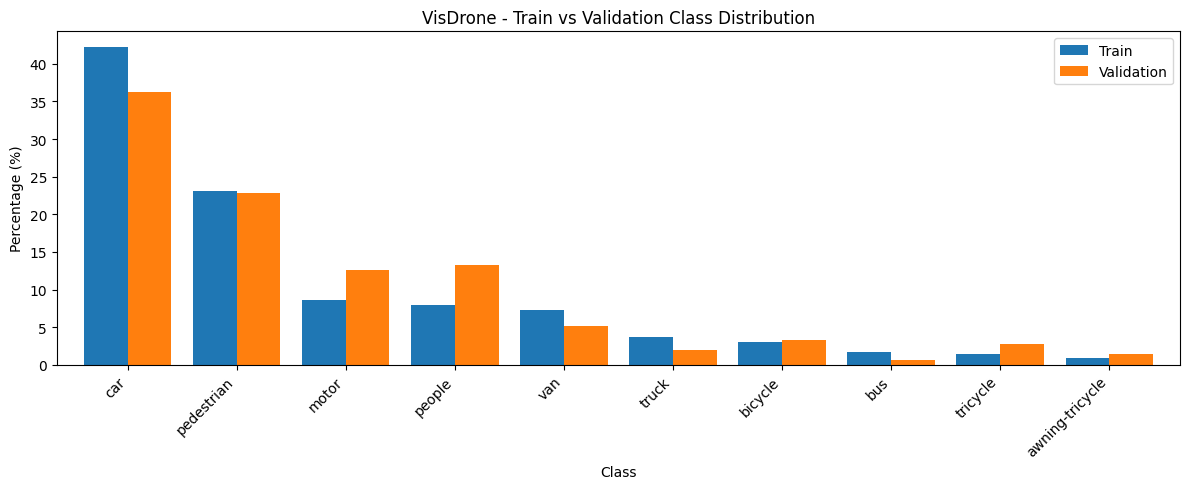

In [45]:
import matplotlib.pyplot as plt

ax = comparison.plot(
    x="class_name",
    y=["percentage_train", "percentage_val"],
    kind="bar",
    figsize=(12, 5),
    width=0.8
)

plt.title("VisDrone - Train vs Validation Class Distribution")
plt.xlabel("Class")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=45, ha="right")
plt.legend(["Train", "Validation"])
plt.tight_layout()
plt.show()

#### Objects Per Image

In [46]:
def get_objects_per_image(objects_df, all_images_df):

    counts = (
        objects_df.groupby("image_id")
        .size()
        .rename("object_count")
    )

    result = all_images_df[["image_id"]].drop_duplicates().merge(
        counts,
        on="image_id",
        how="left"
    )

    result["object_count"] = (
        result["object_count"].fillna(0).astype(int)
    )

    return result


train_objects_per_image = get_objects_per_image(
    train_objects, train_image_sizes
)

val_objects_per_image = get_objects_per_image(
    val_objects, val_image_sizes
)

In [48]:
import pandas as pd

def get_object_statistics(df):
    counts = df["object_count"]

    return {
        "Total Images": len(df),
        "Total Objects": counts.sum(),
        "Images With Objects": (counts > 0).sum(),
        "Images Without Objects": (counts == 0).sum(),
        "Mean": counts.mean(),
        "Median": counts.median(),
        "Std": counts.std(),
        "Min": counts.min(),
        "25%": counts.quantile(0.25),
        "50%": counts.quantile(0.50),
        "75%": counts.quantile(0.75),
        "90%": counts.quantile(0.90),
        "95%": counts.quantile(0.95),
        "99%": counts.quantile(0.99),
        "Max": counts.max()
    }


# Train ve Validation istatistiklerini hesapla
train_stats = get_object_statistics(train_objects_per_image)
val_stats = get_object_statistics(val_objects_per_image)

# Yan yana karşılaştırma tablosu oluştur
statistics_df = pd.DataFrame({
    "Train": train_stats,
    "Validation": val_stats
})

display(statistics_df)

,Train,Validation
Total Images,6471.000000,548.000000
Total Objects,343204.000000,38759.000000
Images With Objects,6471.000000,548.000000
Images Without Objects,0.000000,0.000000
Mean,53.037243,70.728102
Median,42.000000,65.000000
Std,43.841999,45.995439
Min,1.000000,1.000000
25%,24.000000,39.750000
50%,42.000000,65.000000


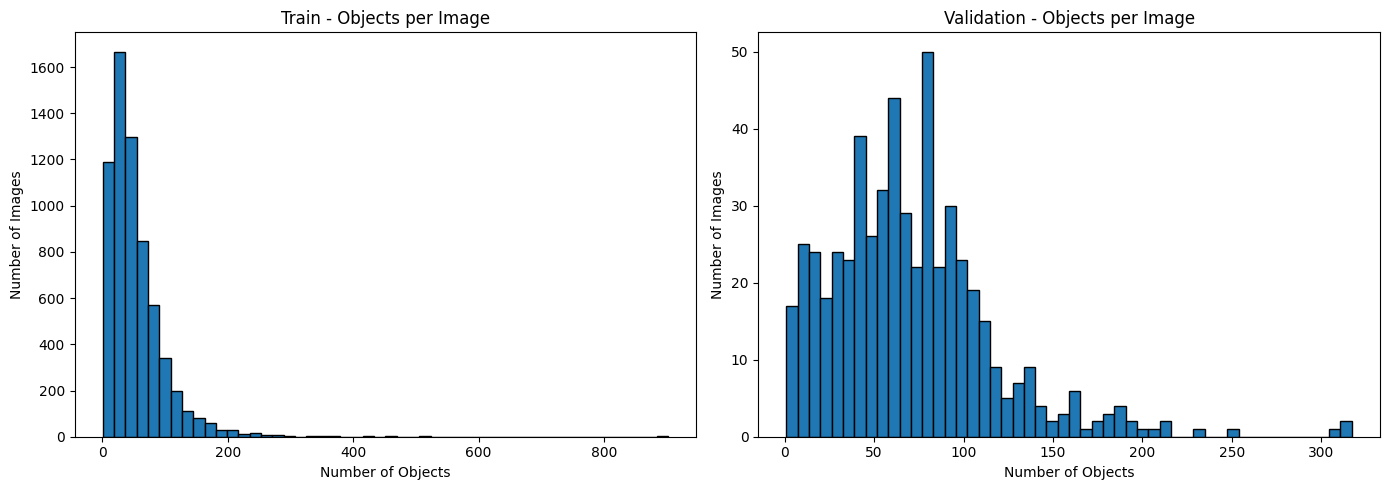

In [49]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(
    train_objects_per_image["object_count"],
    bins=50,
    edgecolor="black"
)
axes[0].set_title("Train - Objects per Image")
axes[0].set_xlabel("Number of Objects")
axes[0].set_ylabel("Number of Images")

axes[1].hist(
    val_objects_per_image["object_count"],
    bins=50,
    edgecolor="black"
)
axes[1].set_title("Validation - Objects per Image")
axes[1].set_xlabel("Number of Objects")
axes[1].set_ylabel("Number of Images")

plt.tight_layout()
plt.show()

In [51]:
def check_dense_images(df, threshold=300):
    dense_images = df[df["object_count"] > threshold]

    print(f"{threshold}'den fazla nesne içeren görüntü:", len(dense_images))
    print(f"Toplam görüntülere oranı: %{len(dense_images) / len(df) * 100:.2f}")

    return dense_images.sort_values("object_count", ascending=False)


print("TRAIN")
train_dense = check_dense_images(train_objects_per_image)

print("\nVALIDATION")
val_dense = check_dense_images(val_objects_per_image)

display(train_dense)
display(val_dense.head(10))

TRAIN
300'den fazla nesne içeren görüntü: 12
Toplam görüntülere oranı: %0.19

VALIDATION
300'den fazla nesne içeren görüntü: 3
Toplam görüntülere oranı: %0.55


,image_id,object_count
51,0000059_01886_d_0000114,902
221,0000137_02220_d_0000163,512
264,0000143_01681_d_0000056,462
196,0000126_11844_d_0000130,431
254,0000142_04458_d_0000045,370
1979,9999943_00000_d_0000049,351
209,0000135_01327_d_0000151,348
220,0000137_01824_d_0000162,346
261,0000143_00881_d_0000052,342
253,0000142_04058_d_0000043,306


,image_id,object_count
374,0000295_02400_d_0000033,317
372,0000295_02000_d_0000031,311
371,0000295_01800_d_0000030,306


Image size: (960, 540)


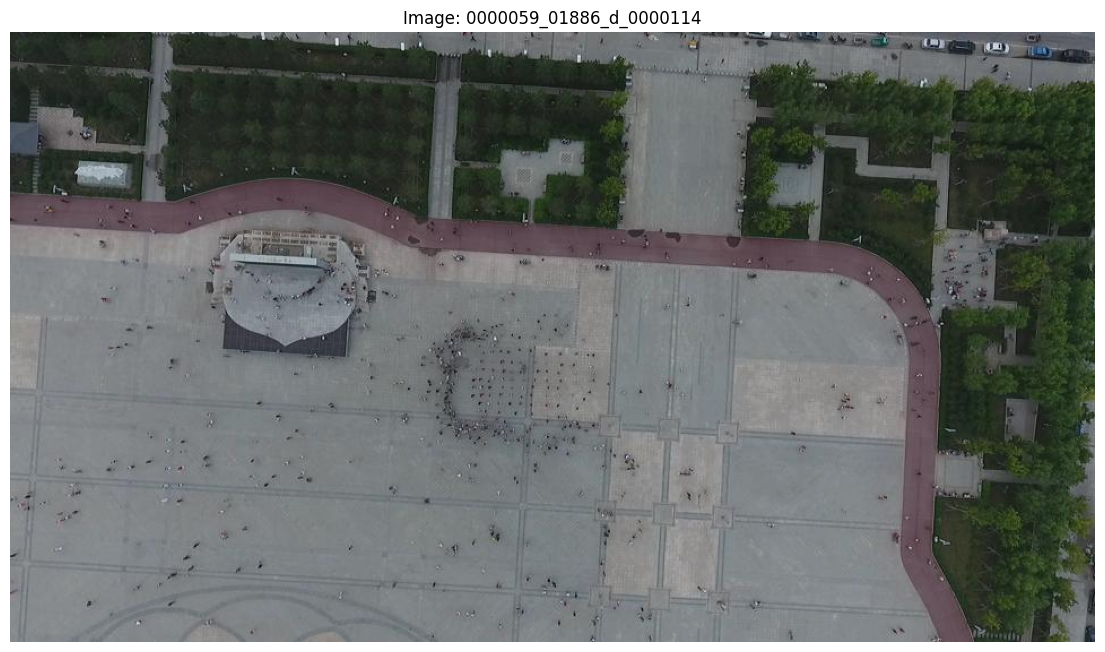

In [52]:
from PIL import Image
import matplotlib.pyplot as plt

image_id = "0000059_01886_d_0000114"

image_path = TRAIN_DIR / "images" / f"{image_id}.jpg"

image = Image.open(image_path)

print("Image size:", image.size)

plt.figure(figsize=(14, 10))
plt.imshow(image)
plt.axis("off")
plt.title(f"Image: {image_id}")
plt.show()

Object count: 902


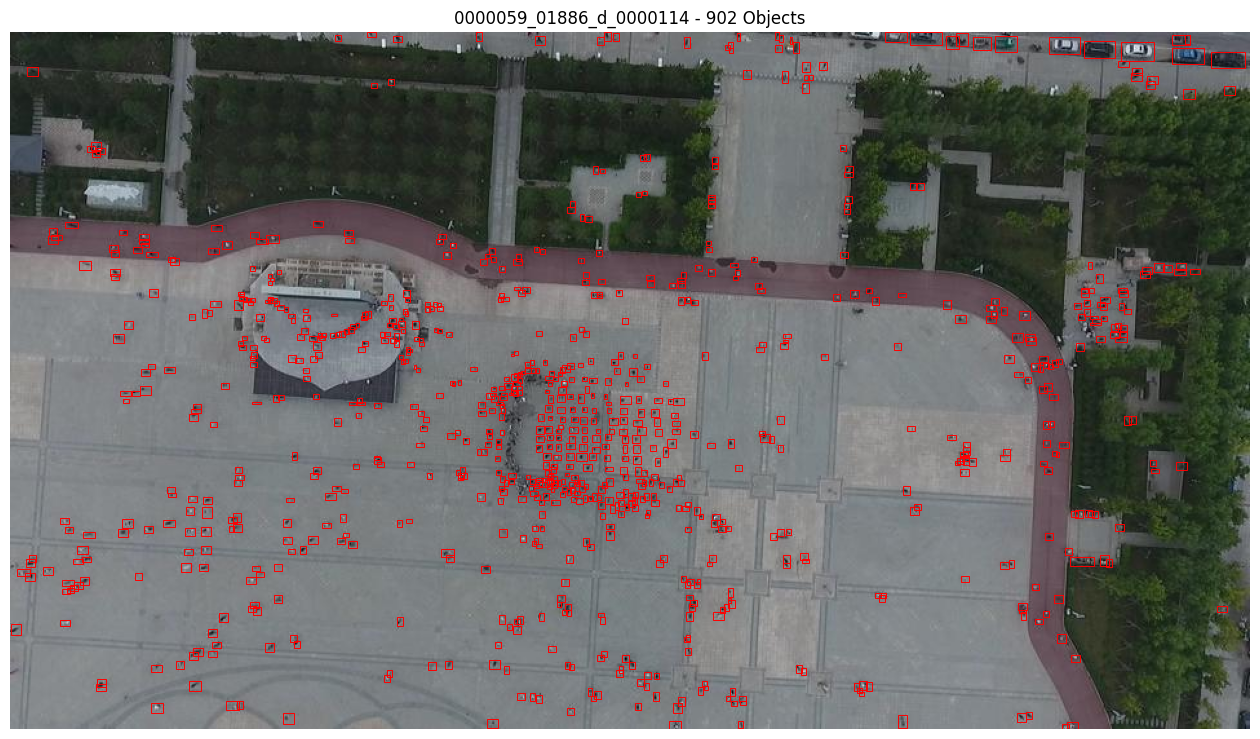

In [53]:
import matplotlib.patches as patches

# Bu görüntüye ait geçerli annotation'ları seç
image_objects = train_objects[
    train_objects["image_id"] == image_id
]

print("Object count:", len(image_objects))

fig, ax = plt.subplots(figsize=(16, 12))

ax.imshow(image)

for _, obj in image_objects.iterrows():

    x = obj["bbox_left"]
    y = obj["bbox_top"]
    w = obj["bbox_width"]
    h = obj["bbox_height"]

    rect = patches.Rectangle(
        (x, y),
        w,
        h,
        linewidth=0.7,
        edgecolor="red",
        facecolor="none"
    )

    ax.add_patch(rect)

ax.set_title(f"{image_id} - {len(image_objects)} Objects")
ax.axis("off")

plt.show()

In [54]:
class_counts = (
    image_objects["class_name"]
    .value_counts()
    .rename_axis("class_name")
    .reset_index(name="count")
)

display(class_counts)

,class_name,count
0,pedestrian,842
1,people,46
2,car,8
3,tricycle,3
4,motor,2
5,awning-tricycle,1


In [55]:
pedestrians = image_objects[
    image_objects["class_name"] == "pedestrian"
].copy()

pedestrians["bbox_area"] = (
    pedestrians["bbox_width"] *
    pedestrians["bbox_height"]
)

display(
    pedestrians[
        ["bbox_width", "bbox_height", "bbox_area"]
    ].describe()
)

,bbox_width,bbox_height,bbox_area
count,842.000000,842.000000,842.000000
mean,5.243468,4.678147,25.356295
std,1.562449,1.208264,12.219802
min,2.000000,2.000000,6.000000
25%,4.000000,4.000000,16.000000
50%,5.000000,5.000000,24.000000
75%,6.000000,5.000000,30.000000
max,10.000000,10.000000,72.000000


In [56]:
def get_bbox_statistics_by_class(df):

    data = df.copy()

    # Bounding box alanını hesapla
    data["bbox_area"] = (
        data["bbox_width"] * data["bbox_height"]
    )

    # Sınıflara göre istatistikleri hesapla
    stats = data.groupby("class_name").agg(
        object_count=("bbox_width", "count"),

        width_min=("bbox_width", "min"),
        width_max=("bbox_width", "max"),
        width_mean=("bbox_width", "mean"),
        width_median=("bbox_width", "median"),

        height_min=("bbox_height", "min"),
        height_max=("bbox_height", "max"),
        height_mean=("bbox_height", "mean"),
        height_median=("bbox_height", "median"),

        area_min=("bbox_area", "min"),
        area_max=("bbox_area", "max"),
        area_mean=("bbox_area", "mean"),
        area_median=("bbox_area", "median")
    )

    return stats.round(2)


train_bbox_stats = get_bbox_statistics_by_class(train_objects)
val_bbox_stats = get_bbox_statistics_by_class(val_objects)

print("TRAIN - BBOX STATISTICS BY CLASS")
display(train_bbox_stats)

print("VALIDATION - BBOX STATISTICS BY CLASS")
display(val_bbox_stats)

TRAIN - BBOX STATISTICS BY CLASS


,object_count,width_min,width_max,width_mean,width_median,height_min,height_max,height_mean,height_median,area_min,area_max,area_mean,area_median
class_name,,,,,,,,,,,,,
awning-tricycle,3246,3,338,45.28,36.0,4,350,45.05,36.0,16,66048,2905.23,1320.0
bicycle,10480,3,332,29.46,24.0,1,271,31.21,26.0,9,60756,1221.88,612.0
bus,5926,3,690,67.07,49.0,4,663,65.63,48.0,12,324300,6971.60,2378.0
car,144866,2,717,51.26,38.0,1,790,40.61,29.0,3,328640,3289.26,1104.0
motor,29647,2,260,26.65,22.0,1,280,27.74,23.0,8,64680,993.92,512.0
pedestrian,79337,2,273,16.22,13.0,2,321,30.73,25.0,6,43656,712.29,315.0
people,27059,2,215,16.43,13.0,1,338,24.71,20.0,3,72670,591.58,273.0
tricycle,4812,3,411,45.10,36.0,3,347,40.40,33.0,9,100170,2547.02,1188.0
truck,12875,3,983,67.73,49.0,3,704,60.72,43.0,9,315202,6473.57,2145.0


VALIDATION - BBOX STATISTICS BY CLASS


,object_count,width_min,width_max,width_mean,width_median,height_min,height_max,height_mean,height_median,area_min,area_max,area_mean,area_median
class_name,,,,,,,,,,,,,
awning-tricycle,532,4,331,33.67,28.0,5,197,34.37,30.0,20,65207,1556.30,858.0
bicycle,1287,3,176,23.17,20.0,3,242,24.82,22.0,15,25894,708.03,432.0
bus,251,4,519,51.13,34.0,5,276,51.14,37.0,24,92382,4646.20,1242.0
car,14064,2,577,47.74,38.0,2,616,35.18,27.0,4,355432,2495.86,1056.0
motor,4886,2,249,22.42,19.0,2,236,23.91,21.0,6,58764,684.58,400.0
pedestrian,8844,2,157,13.08,11.0,3,385,30.75,28.0,6,58135,537.89,295.0
people,5125,2,115,14.74,13.0,3,175,24.10,22.0,8,20125,458.00,280.0
tricycle,1045,2,189,35.99,30.0,4,146,31.16,26.0,8,25704,1459.07,805.0
truck,750,5,580,57.69,43.0,5,547,50.46,34.0,25,317260,4950.17,1491.0


In [57]:
import pandas as pd

def get_object_size_distribution(df):

    data = df.copy()

    # Bounding box alanı
    data["bbox_area"] = (
        data["bbox_width"] * data["bbox_height"]
    )

    # Alanlarına göre boyut kategorileri
    data["size_category"] = pd.cut(
        data["bbox_area"],
        bins=[0, 32**2, 96**2, float("inf")],
        labels=["Small", "Medium", "Large"],
        right=False
    )

    # Her sınıfta kaç Small / Medium / Large var?
    counts = pd.crosstab(
        data["class_name"],
        data["size_category"]
    )

    # Sınıf içindeki yüzdeleri hesapla
    percentages = (
        counts.div(counts.sum(axis=1), axis=0) * 100
    )

    return counts, percentages.round(2)


train_size_counts, train_size_percentages = (
    get_object_size_distribution(train_objects)
)

val_size_counts, val_size_percentages = (
    get_object_size_distribution(val_objects)
)

print("TRAIN - SIZE COUNTS")
display(train_size_counts)

print("TRAIN - SIZE PERCENTAGES")
display(train_size_percentages)

print("VALIDATION - SIZE COUNTS")
display(val_size_counts)

print("VALIDATION - SIZE PERCENTAGES")
display(val_size_percentages)

TRAIN - SIZE COUNTS


size_category,Small,Medium,Large
class_name,,,
awning-tricycle,1365,1695,186
bicycle,7100,3253,127
bus,1657,3269,1000
car,69801,63125,11940
motor,21964,7416,267
pedestrian,65233,13798,306
people,23505,3455,99
tricycle,2178,2424,210
truck,3984,6724,2167


TRAIN - SIZE PERCENTAGES


size_category,Small,Medium,Large
class_name,,,
awning-tricycle,42.05,52.22,5.73
bicycle,67.75,31.04,1.21
bus,27.96,55.16,16.87
car,48.18,43.57,8.24
motor,74.09,25.01,0.90
pedestrian,82.22,17.39,0.39
people,86.87,12.77,0.37
tricycle,45.26,50.37,4.36
truck,30.94,52.23,16.83


VALIDATION - SIZE COUNTS


size_category,Small,Medium,Large
class_name,,,
awning-tricycle,305,222,5
bicycle,1053,231,3
bus,116,103,32
car,6902,6383,779
motor,3977,902,7
pedestrian,7746,1075,23
people,4631,489,5
tricycle,620,413,12
truck,289,374,87


VALIDATION - SIZE PERCENTAGES


size_category,Small,Medium,Large
class_name,,,
awning-tricycle,57.33,41.73,0.94
bicycle,81.82,17.95,0.23
bus,46.22,41.04,12.75
car,49.08,45.39,5.54
motor,81.40,18.46,0.14
pedestrian,87.58,12.16,0.26
people,90.36,9.54,0.10
tricycle,59.33,39.52,1.15
truck,38.53,49.87,11.60


In [58]:
def get_detailed_size_distribution(df):

    data = df.copy()

    data["bbox_area"] = (
        data["bbox_width"] * data["bbox_height"]
    )

    bins = [0, 16, 64, 256, 1024, 9216, float("inf")]

    labels = [
        "Extremely Tiny",
        "Tiny",
        "Very Small",
        "Small",
        "Medium",
        "Large"
    ]

    data["size_group"] = pd.cut(
        data["bbox_area"],
        bins=bins,
        labels=labels,
        right=False
    )

    counts = pd.crosstab(
        data["class_name"],
        data["size_group"]
    )

    percentages = (
        counts.div(counts.sum(axis=1), axis=0) * 100
    ).round(2)

    return counts, percentages


train_detailed_counts, train_detailed_pct = (
    get_detailed_size_distribution(train_objects)
)

val_detailed_counts, val_detailed_pct = (
    get_detailed_size_distribution(val_objects)
)

print("TRAIN - DETAILED SIZE COUNTS")
display(train_detailed_counts)

print("TRAIN - DETAILED SIZE PERCENTAGES")
display(train_detailed_pct)

print("VALIDATION - DETAILED SIZE COUNTS")
display(val_detailed_counts)

print("VALIDATION - DETAILED SIZE PERCENTAGES")
display(val_detailed_pct)

TRAIN - DETAILED SIZE COUNTS


size_group,Extremely Tiny,Tiny,Very Small,Small,Medium,Large
class_name,,,,,,
awning-tricycle,0,52,340,973,1695,186
bicycle,10,362,2021,4707,3253,127
bus,1,60,361,1235,3269,1000
car,394,4421,20618,44368,63125,11940
motor,69,1644,6912,13339,7416,267
pedestrian,377,7386,26556,30914,13798,306
people,191,2774,10023,10517,3455,99
tricycle,2,70,581,1525,2424,210
truck,4,120,933,2927,6724,2167


TRAIN - DETAILED SIZE PERCENTAGES


size_group,Extremely Tiny,Tiny,Very Small,Small,Medium,Large
class_name,,,,,,
awning-tricycle,0.00,1.60,10.47,29.98,52.22,5.73
bicycle,0.10,3.45,19.28,44.91,31.04,1.21
bus,0.02,1.01,6.09,20.84,55.16,16.87
car,0.27,3.05,14.23,30.63,43.57,8.24
motor,0.23,5.55,23.31,44.99,25.01,0.90
pedestrian,0.48,9.31,33.47,38.97,17.39,0.39
people,0.71,10.25,37.04,38.87,12.77,0.37
tricycle,0.04,1.45,12.07,31.69,50.37,4.36
truck,0.03,0.93,7.25,22.73,52.23,16.83


VALIDATION - DETAILED SIZE COUNTS


size_group,Extremely Tiny,Tiny,Very Small,Small,Medium,Large
class_name,,,,,,
awning-tricycle,0,14,75,216,222,5
bicycle,1,48,347,657,231,3
bus,0,9,28,79,103,32
car,28,650,2056,4168,6383,779
motor,26,304,1382,2265,902,7
pedestrian,17,595,3346,3788,1075,23
people,26,516,1871,2218,489,5
tricycle,2,37,153,428,413,12
truck,0,11,80,198,374,87


VALIDATION - DETAILED SIZE PERCENTAGES


size_group,Extremely Tiny,Tiny,Very Small,Small,Medium,Large
class_name,,,,,,
awning-tricycle,0.00,2.63,14.10,40.60,41.73,0.94
bicycle,0.08,3.73,26.96,51.05,17.95,0.23
bus,0.00,3.59,11.16,31.47,41.04,12.75
car,0.20,4.62,14.62,29.64,45.39,5.54
motor,0.53,6.22,28.28,46.36,18.46,0.14
pedestrian,0.19,6.73,37.83,42.83,12.16,0.26
people,0.51,10.07,36.51,43.28,9.54,0.10
tricycle,0.19,3.54,14.64,40.96,39.52,1.15
truck,0.00,1.47,10.67,26.40,49.87,11.60


In [59]:
def get_resolution_distribution(df):

    resolution_counts = (
        df.groupby(["image_width", "image_height"])
        .size()
        .reset_index(name="image_count")
        .sort_values("image_count", ascending=False)
    )

    resolution_counts["percentage"] = (
        resolution_counts["image_count"]
        / resolution_counts["image_count"].sum()
        * 100
    ).round(2)

    return resolution_counts


train_resolutions = get_resolution_distribution(train_image_sizes)
val_resolutions = get_resolution_distribution(val_image_sizes)

print("TRAIN RESOLUTIONS")
display(train_resolutions)

print("VALIDATION RESOLUTIONS")
display(val_resolutions)

TRAIN RESOLUTIONS


,image_width,image_height,image_count,percentage
7,1400,1050,2498,38.60
6,1400,788,1299,20.07
10,2000,1500,772,11.93
3,1360,765,743,11.48
8,1916,1078,537,8.30
9,1920,1080,339,5.24
1,960,540,250,3.86
5,1398,1048,30,0.46
0,480,360,1,0.02
2,1344,756,1,0.02


VALIDATION RESOLUTIONS


,image_width,image_height,image_count,percentage
1,1360,765,408,74.45
0,960,540,121,22.08
2,1920,1080,19,3.47


In [63]:
def calculate_resized_bbox_sizes(df):

    data = df.copy()

    # Resize katsayıları
    data["scale_x"] = 640 / data["image_width"]
    data["scale_y"] = 640 / data["image_height"]

    # Yeni bounding box boyutları
    data["resized_width"] = (
        data["bbox_width"] * data["scale_x"]
    )

    data["resized_height"] = (
        data["bbox_height"] * data["scale_y"]
    )

    # Yeni bounding box alanı
    data["resized_area"] = (
        data["resized_width"] * data["resized_height"]
    )

    return data


train_resized = calculate_resized_bbox_sizes(train_objects)
val_resized = calculate_resized_bbox_sizes(val_objects)

In [64]:
def get_resized_bbox_stats(df):

    return df.groupby("class_name").agg(
        object_count=("resized_width", "count"),

        width_mean=("resized_width", "mean"),
        width_median=("resized_width", "median"),

        height_mean=("resized_height", "mean"),
        height_median=("resized_height", "median"),

        area_mean=("resized_area", "mean"),
        area_median=("resized_area", "median")
    ).round(2)


print("TRAIN - RESIZED BBOX STATISTICS")
display(get_resized_bbox_stats(train_resized))

print("VALIDATION - RESIZED BBOX STATISTICS")
display(get_resized_bbox_stats(val_resized))

TRAIN - RESIZED BBOX STATISTICS


,object_count,width_mean,width_median,height_mean,height_median,area_mean,area_median
class_name,,,,,,,
awning-tricycle,3246,17.96,14.36,28.53,23.42,712.44,344.27
bicycle,10480,11.56,9.33,18.43,15.41,273.22,143.59
bus,5926,29.43,21.94,47.35,35.74,2085.42,768.56
car,144866,21.40,16.00,25.72,18.68,838.39,299.54
motor,29647,11.13,9.14,17.76,15.24,248.76,142.11
pedestrian,79337,6.95,5.49,20.44,17.07,192.52,94.20
people,27059,6.85,5.65,16.17,13.41,153.40,77.41
tricycle,4812,18.67,15.09,27.28,22.59,678.82,355.53
truck,12875,28.54,21.03,40.11,29.24,1747.14,613.01


VALIDATION - RESIZED BBOX STATISTICS


,object_count,width_mean,width_median,height_mean,height_median,area_mean,area_median
class_name,,,,,,,
awning-tricycle,532,17.18,14.59,31.25,25.93,712.96,365.35
bicycle,1287,11.11,9.41,21.18,18.41,290.01,179.52
bus,251,25.17,16.00,44.87,32.00,1962.32,508.65
car,14064,22.88,18.35,30.00,23.42,1001.03,433.06
motor,4886,11.16,9.33,21.32,18.96,303.57,175.01
pedestrian,8844,6.49,5.18,27.15,23.70,238.99,125.59
people,5125,7.49,6.59,21.77,20.08,209.10,127.21
tricycle,1045,18.88,15.53,28.86,24.89,692.99,391.11
truck,750,29.08,21.65,44.83,30.95,2189.67,661.75


In [65]:
def get_small_width_percentages(df):

    results = []

    for class_name, group in df.groupby("class_name"):

        total = len(group)

        results.append({
            "class_name": class_name,
            "object_count": total,

            "width_lt_4_pct": (
                (group["resized_width"] < 4).mean() * 100
            ),

            "width_lt_8_pct": (
                (group["resized_width"] < 8).mean() * 100
            ),

            "width_lt_16_pct": (
                (group["resized_width"] < 16).mean() * 100
            ),

            "both_lt_8_pct": (
                (
                    (group["resized_width"] < 8) &
                    (group["resized_height"] < 8)
                ).mean() * 100
            )
        })

    return pd.DataFrame(results).set_index("class_name").round(2)


train_width_pct = get_small_width_percentages(train_resized)
val_width_pct = get_small_width_percentages(val_resized)

print("TRAIN - SMALL WIDTH PERCENTAGES")
display(train_width_pct)

print("VALIDATION - SMALL WIDTH PERCENTAGES")
display(val_width_pct)

TRAIN - SMALL WIDTH PERCENTAGES


,object_count,width_lt_4_pct,width_lt_8_pct,width_lt_16_pct,both_lt_8_pct
class_name,,,,,
awning-tricycle,3246,5.21,22.27,55.61,5.67
bicycle,10480,14.35,41.23,76.48,10.89
bus,5926,2.55,11.93,35.08,2.43
car,144866,4.36,19.64,48.93,10.98
motor,29647,13.90,41.73,78.44,12.61
pedestrian,79337,30.66,70.36,93.88,11.85
people,27059,28.35,69.74,95.37,19.04
tricycle,4812,3.87,19.47,52.00,4.51
truck,12875,2.30,12.49,36.38,3.57


VALIDATION - SMALL WIDTH PERCENTAGES


,object_count,width_lt_4_pct,width_lt_8_pct,width_lt_16_pct,both_lt_8_pct
class_name,,,,,
awning-tricycle,532,2.82,19.17,56.20,1.32
bicycle,1287,12.04,38.77,78.71,3.11
bus,251,2.39,18.73,48.21,1.59
car,14064,3.47,15.64,43.12,7.14
motor,4886,11.44,40.36,79.19,4.32
pedestrian,8844,29.79,73.22,96.36,2.53
people,5125,19.18,62.67,94.97,4.92
tricycle,1045,3.44,18.37,50.81,2.87
truck,750,1.87,13.07,34.27,1.33
